<a href="https://colab.research.google.com/github/fadzankerim/Network-Intrusion-Detection-System/blob/main/EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# Postavke za vizualizaciju
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
sns.set_palette('Set2')

# Prikaz svih kolona u DataFrame-u
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

print('===========Biblioteke uspješno učitane===========')

===========Biblioteke uspješno učitane===========


In [ ]:
#from google.colab import drive
#drive.mount('/content/drive')

#DATASET_PATH = '/content/drive/MyDrive/MPVI/Dataset/'
#DATASET_PATH = 'https://drive.google.com/drive/folders/1wqUUXHiIzMHGnOgqezpQDQyDzJ8fzXOm?usp=drive_link'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import os
import sys
from pathlib import Path

# ID i link tvog Google Drive foldera sa datasetom:
# https://drive.google.com/drive/folders/1wqUUXHiIzMHGnOgqezpQDQyDzJ8fzXOm?usp=drive_link
GDRIVE_FOLDER_ID = '1wqUUXHiIzMHGnOgqezpQDQyDzJ8fzXOm'
GDRIVE_FOLDER_URL = f'https://drive.google.com/drive/folders/{GDRIVE_FOLDER_ID}'

# 1. Pokušaj montiranja Google Drive-a
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
except Exception as e:
    print(f'ℹ Google Drive mount preskočen ili nije na Colab-u: {e}')

def resolve_dataset_directory(folder_id=GDRIVE_FOLDER_ID):
    """
    Automatski pronalazi ili preuzima UNSW-NB15 dataset.
    Omogućava da kod radi bez greške i vlasniku i svim kolegama sa linkom!
    """
    # Poznate putanje
    candidate_paths = [
        Path('/content/Dataset'),
        Path('/content/drive/MyDrive/MPVI/Dataset'),
        Path('/content/drive/MyDrive/Dataset'),
        Path('./Dataset'),
        Path('../Dataset')
    ]

    # 1. Provjera poznatih lokacija
    for p in candidate_paths:
        if p.exists() and len(list(p.glob('**/UNSW_NB15_training-set.csv'))) > 0:
            found_file = list(p.glob('**/UNSW_NB15_training-set.csv'))[0]
            ds_root = found_file.parent.parent if found_file.parent.name == 'Training and Testing Sets' else found_file.parent
            print(f'✅ Dataset pronađen na postojećoj lokaciji: {ds_root}')
            return str(ds_root)

    # 2. Pretraga montiranog Google Drive-a ako postoji (npr. prečica kod kolege)
    drive_root = Path('/content/drive/MyDrive')
    if drive_root.exists():
        print('🔍 Pretražujem montirani Google Drive za UNSW-NB15 datasetom...')
        found = list(drive_root.glob('**/UNSW_NB15_training-set.csv'))
        if found:
            ds_root = found[0].parent.parent if found[0].parent.name == 'Training and Testing Sets' else found[0].parent
            print(f'✅ Dataset automatski detektovan na Drive-u: {ds_root}')
            return str(ds_root)

    # 3. Automatski download sa javnog Google Drive linka preko gdown
    print('📥 Dataset nije pronađen na Drive-u.')
    print('🚀 Pokrećem automatsko preuzimanje preko Google Drive linka u /content/Dataset/ ...')

    try:
        import gdown
    except ImportError:
        import subprocess
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gdown'], check=True)
        import gdown

    download_dir = Path('/content/Dataset')
    download_dir.mkdir(parents=True, exist_ok=True)

    try:
        gdown.download_folder(id=folder_id, output=str(download_dir), quiet=False, use_cookies=False)
    except Exception as err:
        print(f'Pokušavam download preko URL-a: {err}')
        gdown.download_folder(url=GDRIVE_FOLDER_URL, output=str(download_dir), quiet=False)

    found = list(download_dir.glob('**/UNSW_NB15_training-set.csv'))
    if found:
        ds_root = found[0].parent.parent if found[0].parent.name == 'Training and Testing Sets' else found[0].parent
        print(f'✅ Dataset uspješno preuzet na: {ds_root}')
        return str(ds_root)

    return str(download_dir)

# Određivanje putanja
DATASET_PATH = resolve_dataset_directory()
if not DATASET_PATH.endswith('/'):
    DATASET_PATH += '/'

# Dinamičko mapiranje pojedinačnih fajlova (otporno na varijacije u folderima)
train_matches = list(Path(DATASET_PATH).glob('**/UNSW_NB15_training-set.csv'))
test_matches = list(Path(DATASET_PATH).glob('**/UNSW_NB15_testing-set.csv'))
features_matches = list(Path(DATASET_PATH).glob('**/NUSW-NB15_features.csv'))

TRAIN_PATH = str(train_matches[0]) if train_matches else DATASET_PATH + 'Training and Testing Sets/UNSW_NB15_training-set.csv'
TEST_PATH = str(test_matches[0]) if test_matches else DATASET_PATH + 'Training and Testing Sets/UNSW_NB15_testing-set.csv'
FEATURES_PATH = str(features_matches[0]) if features_matches else DATASET_PATH + 'NUSW-NB15_features.csv'

print(f' DATASET_PATH: {DATASET_PATH}')
print(f' TRAIN_PATH:   {TRAIN_PATH}')
print(f' TEST_PATH:    {TEST_PATH}')
print(f' FEATURES_PATH:{FEATURES_PATH}')


Mounted at /content/drive
✅ Dataset pronađen na postojećoj lokaciji: /content/drive/MyDrive/MPVI/Dataset
 DATASET_PATH: /content/drive/MyDrive/MPVI/Dataset/
 TRAIN_PATH:   /content/drive/MyDrive/MPVI/Dataset/Training and Testing Sets/UNSW_NB15_training-set.csv
 TEST_PATH:    /content/drive/MyDrive/MPVI/Dataset/Training and Testing Sets/UNSW_NB15_testing-set.csv
 FEATURES_PATH:/content/drive/MyDrive/MPVI/Dataset/NUSW-NB15_features.csv


In [5]:
# Učitavanje training i testing seta
TRAIN_PATH = DATASET_PATH + 'Training and Testing Sets/UNSW_NB15_training-set.csv'
TEST_PATH  = DATASET_PATH + 'Training and Testing Sets/UNSW_NB15_testing-set.csv'

df_train = pd.read_csv(TRAIN_PATH)
df_test  = pd.read_csv(TEST_PATH)

print(f'Training set: {df_train.shape[0]:,} zapisa, {df_train.shape[1]} kolona')
print(f'Testing set:  {df_test.shape[0]:,} zapisa, {df_test.shape[1]} kolona')
print(f'Ukupno:       {df_train.shape[0] + df_test.shape[0]:,} zapisa')

Training set: 175,341 zapisa, 45 kolona
Testing set:  82,332 zapisa, 45 kolona
Ukupno:       257,673 zapisa


In [6]:
# Kombinovanje za potpunu analizu
df_train['source'] = 'train'
df_test['source']  = 'test'
df = pd.concat([df_train, df_test], axis=0, ignore_index=True)

print(f'Kombinovani dataset: {df.shape[0]:,} zapisa, {df.shape[1]} kolona')

Kombinovani dataset: 257,673 zapisa, 46 kolona


In [7]:
# Učitavanje opisa feature-a
features_df = pd.read_csv(DATASET_PATH + 'NUSW-NB15_features.csv', encoding='latin1')
print('Feature-i dataseta:')
display(features_df)

Feature-i dataseta:


,No.,Name,Type,Description
0,1,srcip,nominal,Source IP address
1,2,sport,integer,Source port number
2,3,dstip,nominal,Destination IP address
3,4,dsport,integer,Destination port number
4,5,proto,nominal,Transaction protocol
5,6,state,nominal,Indicates to the state and its dependent proto...
6,7,dur,Float,Record total duration
7,8,sbytes,Integer,Source to destination transaction bytes
8,9,dbytes,Integer,Destination to source transaction bytes
9,10,sttl,Integer,Source to destination time to live value


In [8]:
#UCITAVANJE SIROVOG DATASETA SA 2.5M zapisa bez headera

column_names = [
    'srcip', 'sport', 'dstip', 'dsport', 'proto', 'state', 'dur',
    'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'service',
    'Sload', 'Dload', 'Spkts', 'Dpkts', 'swin', 'dwin', 'stcpb',
    'dtcpb', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len',
    'Sjit', 'Djit', 'Stime', 'Ltime', 'Sintpkt', 'Dintpkt',
    'tcprtt', 'synack', 'ackdat', 'is_sm_ips_ports', 'ct_state_ttl',
    'ct_flw_http_mthd', 'is_ftp_login', 'ct_ftp_cmd', 'ct_srv_src',
    'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm',
    'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'attack_cat', 'label'
]
raw_files = [f'{DATASET_PATH}UNSW-NB15_{i}.csv' for i in range(1, 5)]
df_raw = pd.concat(
    [pd.read_csv(f, header=None, names=column_names, low_memory=False) for f in raw_files],
    ignore_index=True
)
print(f'Sirovi dataset: {df_raw.shape[0]:,} zapisa, {df_raw.shape[1]} kolona')

Sirovi dataset: 2,540,047 zapisa, 49 kolona


In [10]:
# Prvih 5 redova
print('=== Prvih 5 redova ===')
display(df.head())

=== Prvih 5 redova ===


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label,source
0,1,0.1215,tcp,-,FIN,6,4,258,172,74.0875,252,254,14158.9424,8495.3652,0,0,24.2956,8.3750,30.1775,11.8306,255,621772692,2202533631,255,0.0000,0.0000,0.0000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0,train
1,2,0.6499,tcp,-,FIN,14,38,734,42014,78.4734,62,252,8395.1123,503571.3125,2,17,49.9150,15.4329,61.4269,1387.7783,255,1417884146,3077387971,255,0.0000,0.0000,0.0000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0,train
2,3,1.6231,tcp,-,FIN,8,16,364,13186,14.1702,62,252,1572.2719,60929.2305,1,6,231.8756,102.7372,17179.5869,11420.9262,255,2116150707,2963114973,255,0.1119,0.0615,0.0504,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0,train
3,4,1.6816,tcp,ftp,FIN,12,12,628,770,13.6771,62,252,2740.1790,3358.6221,1,3,152.8765,90.2357,259.0802,4991.7847,255,1107119177,1047442890,255,0.0000,0.0000,0.0000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0,train
4,5,0.4495,tcp,-,FIN,10,6,534,268,33.3738,254,252,8561.4990,3987.0598,2,1,47.7503,75.6596,2415.8376,115.8070,255,2436137549,1977154190,255,0.1284,0.0711,0.0572,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0,train


In [11]:
# Posljednjih 5 redova
print('=== Posljednjih 5 redova ===')
display(df.tail())

=== Posljednjih 5 redova ===


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label,source
257668,82328,0.0000,udp,-,INT,2,0,104,0,200000.0051,254,0,83200000.0000,0.0000,0,0,0.0050,0.0000,0.0000,0.0000,0,0,0,0,0.0000,0.0000,0.0000,52,0,0,0,1,2,2,1,1,2,0,0,0,2,1,0,Normal,0,test
257669,82329,1.1061,tcp,-,FIN,20,8,18062,354,24.4101,254,252,124104.3984,2242.1099,7,1,55.8801,143.7000,4798.1310,190.9808,255,1072535109,3284291478,255,0.1732,0.1002,0.0730,903,44,0,0,1,1,2,1,1,1,0,0,0,3,2,0,Normal,0,test
257670,82330,0.0000,arp,-,INT,1,0,46,0,0.0000,0,0,0.0000,0.0000,0,0,60000.7200,0.0000,0.0000,0.0000,0,0,0,0,0.0000,0.0000,0.0000,46,0,0,0,1,2,1,1,1,1,0,0,0,1,1,1,Normal,0,test
257671,82331,0.0000,arp,-,INT,1,0,46,0,0.0000,0,0,0.0000,0.0000,0,0,60000.7320,0.0000,10.9545,0.0000,0,0,0,0,0.0000,0.0000,0.0000,46,0,0,0,1,2,1,1,1,1,0,0,0,1,1,1,Normal,0,test
257672,82332,0.0000,udp,-,INT,2,0,104,0,111111.1072,254,0,46222220.0000,0.0000,0,0,0.0090,0.0000,0.0000,0.0000,0,0,0,0,0.0000,0.0000,0.0000,52,0,0,0,1,2,1,1,1,1,0,0,0,1,1,0,Normal,0,test


In [ ]:
# Informacije o datasetu
print('=== Informacije o datasetu ===')
df.info()

In [12]:
# Tipovi podataka
print('=== Tipovi podataka ===')
print(df.dtypes)
print(f'\nBroj numeričkih kolona: {df.select_dtypes(include=[np.number]).shape[1]}')
print(f'Broj kategoričkih kolona: {df.select_dtypes(include=["object"]).shape[1]}')

=== Tipovi podataka ===
id                     int64
dur                  float64
proto                 object
service               object
state                 object
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload                float64
sloss                  int64
dloss                  int64
sinpkt               float64
dinpkt               float64
sjit                 float64
djit                 float64
swin                   int64
stcpb                  int64
dtcpb                  int64
dwin                   int64
tcprtt               float64
synack               float64
ackdat               float64
smean                  int64
dmean                  int64
trans_depth            int64
response_body_len      int64
ct_srv_src             int64
ct_state_ttl           int64
ct_dst_ltm         

In [ ]:
# Deskriptivna statistika numeričkih kolona
print('=== Deskriptivna statistika (numeričke kolone) ===')
display(df.describe().T)

In [ ]:
# Deskriptivna statistika kategoričkih kolona
print('=== Deskriptivna statistika (kategoričke kolone) ===')
display(df.describe(include='object').T)

In [ ]:
# Oblik dataseta
print(f'Oblik dataseta: {df.shape}')
print(f'Ukupan broj ćelija: {df.shape[0] * df.shape[1]:,}')
print(f'Memorija: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB')

In [ ]:
# Provjera nedostajućih vrijednosti
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Nedostajuće': missing,
    'Procenat (%)': missing_pct
}).sort_values('Nedostajuće', ascending=False)

# Prikaz samo kolona koje imaju nedostajuće vrijednosti
missing_with_values = missing_df[missing_df['Nedostajuće'] > 0]

if len(missing_with_values) > 0:
    print(f'Kolone sa nedostajućim vrijednostima: {len(missing_with_values)}')
    display(missing_with_values)
else:
    print('✅ Nema nedostajućih vrijednosti (NaN) u datasetu.')

print(f'\nUkupno nedostajućih: {missing.sum():,} od {df.shape[0] * df.shape[1]:,} ćelija')

In [ ]:
# Provjera praznih stringova i specijalnih vrijednosti
print('=== Provjera specijalnih vrijednosti ===')
for col in df.select_dtypes(include='object').columns:
    unique_vals = df[col].unique()
    has_dash = '-' in unique_vals
    has_empty = '' in unique_vals
    has_space = ' ' in unique_vals
    if has_dash or has_empty or has_space:
        print(f'  {col}: {"-" if has_dash else ""} {"prazan string" if has_empty else ""} {"razmak" if has_space else ""}')
        if has_dash:
            print(f'    Broj \'-\' vrijednosti: {(df[col] == "-").sum()}')

In [ ]:
# Vizualizacija nedostajućih vrijednosti
fig, ax = plt.subplots(figsize=(14, 5))

null_counts = df.isnull().sum()
if null_counts.sum() > 0:
    null_counts[null_counts > 0].plot(kind='bar', ax=ax, color='coral')
    ax.set_title('Nedostajuće vrijednosti po kolonama', fontsize=14, fontweight='bold')
    ax.set_ylabel('Broj nedostajućih')
    ax.tick_params(axis='x', rotation=45)
else:
    ax.text(0.5, 0.5, 'Nema nedostajućih vrijednosti ✅',
            ha='center', va='center', fontsize=16, transform=ax.transAxes)
    ax.set_title('Nedostajuće vrijednosti', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# Distribucija label-a (0 = Normal, 1 = Attack)
print('=== Distribucija ciljne varijable (label) ===')
label_counts = df['label'].value_counts()
label_pct = df['label'].value_counts(normalize=True) * 100

label_summary = pd.DataFrame({
    'Broj zapisa': label_counts,
    'Procenat (%)': label_pct
})
label_summary.index = ['Normal (0)' if i == 0 else 'Napad (1)' for i in label_summary.index]
display(label_summary)

print(f'\nOdnos Normal:Napad = 1:{label_counts[1]/label_counts[0]:.2f}')

In [ ]:
# Vizualizacija distribucije label-a
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
colors = ['#2ecc71', '#e74c3c']
label_counts.plot(kind='bar', ax=axes[0], color=colors, edgecolor='black')
axes[0].set_title('Distribucija: Normal vs Napad', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Klasa')
axes[0].set_ylabel('Broj zapisa')
axes[0].set_xticklabels(['Normal (0)', 'Napad (1)'], rotation=0)
for i, v in enumerate(label_counts):
    axes[0].text(i, v + 500, f'{v:,}', ha='center', fontweight='bold')

# Pie chart
axes[1].pie(label_counts, labels=['Normal', 'Napad'], autopct='%1.1f%%',
            colors=colors, startangle=90, explode=(0.05, 0.05),
            shadow=True, textprops={'fontsize': 12})
axes[1].set_title('Procentualni odnos klasa', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# Distribucija label-a po Train/Test setu
print('=== Distribucija po Train/Test setovima ===')
cross_tab = pd.crosstab(df['source'], df['label'], margins=True, margins_name='Ukupno')
cross_tab.columns = ['Normal (0)', 'Napad (1)', 'Ukupno']
display(cross_tab)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for idx, src in enumerate(['train', 'test']):
    subset = df[df['source'] == src]['label'].value_counts()
    subset.plot(kind='bar', ax=axes[idx], color=colors, edgecolor='black')
    axes[idx].set_title(f'{src.capitalize()} set', fontsize=14, fontweight='bold')
    axes[idx].set_xticklabels(['Normal', 'Napad'], rotation=0)
    axes[idx].set_ylabel('Broj zapisa')
    for i, v in enumerate(subset):
        axes[idx].text(i, v + 200, f'{v:,}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [13]:
# Pregled kategorija napada
print('=== Kategorije napada ===')
print(f'Jedinstvene kategorije: {df["attack_cat"].nunique()}')
print(f'\nVrijednosti:')
print(df['attack_cat'].unique())

=== Kategorije napada ===
Jedinstvene kategorije: 10

Vrijednosti:
['Normal' 'Backdoor' 'Analysis' 'Fuzzers' 'Shellcode' 'Reconnaissance'
 'Exploits' 'DoS' 'Worms' 'Generic']


In [9]:
# Čišćenje attack_cat kolone (uklanjanje razmaka)
df['attack_cat'] = df['attack_cat'].str.strip()

# Distribucija kategorija napada
attack_counts = df['attack_cat'].value_counts()
attack_pct = df['attack_cat'].value_counts(normalize=True) * 100

attack_summary = pd.DataFrame({
    'Broj zapisa': attack_counts,
    'Procenat (%)': attack_pct.round(2)
})
display(attack_summary)

,Broj zapisa,Procenat (%)
attack_cat,,
Normal,93000,36.0900
Generic,58871,22.8500
Exploits,44525,17.2800
Fuzzers,24246,9.4100
DoS,16353,6.3500
Reconnaissance,13987,5.4300
Analysis,2677,1.0400
Backdoor,2329,0.9000
Shellcode,1511,0.5900


In [ ]:
# Vizualizacija kategorija napada
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar chart – sve kategorije
attack_only = df[df['label'] == 1]['attack_cat'].value_counts()
attack_only.plot(kind='barh', ax=axes[0], color=sns.color_palette('Set2', len(attack_only)),
                 edgecolor='black')
axes[0].set_title('Distribucija kategorija napada', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Broj zapisa')
for i, v in enumerate(attack_only):
    axes[0].text(v + 100, i, f'{v:,}', va='center', fontweight='bold')

# Pie chart – procentualno
axes[1].pie(attack_only, labels=attack_only.index, autopct='%1.1f%%',
            startangle=140, textprops={'fontsize': 9})
axes[1].set_title('Procentualni udio napada po kategoriji', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
# Distribucija kategorija napada po Train/Test setu
fig, ax = plt.subplots(figsize=(14, 6))

attack_cross = pd.crosstab(df[df['label'] == 1]['attack_cat'], df[df['label'] == 1]['source'])
attack_cross.plot(kind='bar', ax=ax, edgecolor='black')
ax.set_title('Kategorije napada: Train vs Test set', fontsize=14, fontweight='bold')
ax.set_xlabel('Kategorija napada')
ax.set_ylabel('Broj zapisa')
ax.tick_params(axis='x', rotation=45)
ax.legend(['Test', 'Train'])

plt.tight_layout()
plt.show()

In [17]:
# Lista numeričkih kolona (bez id, label, source)
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
exclude_cols = ['id', 'label']
numeric_features = [c for c in numeric_cols if c not in exclude_cols]

print(f'Numerički feature-i ({len(numeric_features)}):')
print(numeric_features)

Numerički feature-i (39):
['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']


In [ ]:
# Histogrami za prvih 16 numeričkih feature-a
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()

for idx, col in enumerate(numeric_features[:16]):
    ax = axes[idx]
    df[col].hist(bins=50, ax=ax, color='steelblue', edgecolor='black', alpha=0.7)
    ax.set_title(col, fontsize=11, fontweight='bold')
    ax.set_ylabel('Frekvencija')

plt.suptitle('Distribucije numeričkih feature-a (1/3)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
# Histogrami za sljedećih 16 numeričkih feature-a
remaining = numeric_features[16:32]
if remaining:
    n_plots = len(remaining)
    n_rows = (n_plots + 3) // 4
    fig, axes = plt.subplots(n_rows, 4, figsize=(20, 4 * n_rows))
    axes = axes.flatten()

    for idx, col in enumerate(remaining):
        ax = axes[idx]
        df[col].hist(bins=50, ax=ax, color='darkorange', edgecolor='black', alpha=0.7)
        ax.set_title(col, fontsize=11, fontweight='bold')
        ax.set_ylabel('Frekvencija')

    # Sakrij prazne subplot-ove
    for idx in range(n_plots, len(axes)):
        axes[idx].set_visible(False)

    plt.suptitle('Distribucije numeričkih feature-a (2/3)', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

In [ ]:
# Preostali numerički feature-i
remaining2 = numeric_features[32:]
if remaining2:
    n_plots = len(remaining2)
    n_rows = (n_plots + 3) // 4
    fig, axes = plt.subplots(n_rows, 4, figsize=(20, 4 * n_rows))
    if n_rows == 1:
        axes = [axes] if n_plots == 1 else axes
    axes = np.array(axes).flatten()

    for idx, col in enumerate(remaining2):
        ax = axes[idx]
        df[col].hist(bins=50, ax=ax, color='seagreen', edgecolor='black', alpha=0.7)
        ax.set_title(col, fontsize=11, fontweight='bold')
        ax.set_ylabel('Frekvencija')

    for idx in range(n_plots, len(axes)):
        axes[idx].set_visible(False)

    plt.suptitle('Distribucije numeričkih feature-a (3/3)', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

In [ ]:
# Box plot-ovi za detekciju outlier-a (odabrani feature-i)
selected_features = ['dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss',
                     'sload', 'dload', 'spkts', 'dpkts', 'rate']
# Filtriraj samo postojeće kolone
selected_features = [f for f in selected_features if f in df.columns]

if selected_features:
    n_plots = len(selected_features)
    n_rows = (n_plots + 3) // 4
    fig, axes = plt.subplots(n_rows, 4, figsize=(20, 4 * n_rows))
    axes = np.array(axes).flatten()

    for idx, col in enumerate(selected_features):
        sns.boxplot(data=df, y=col, x='label', ax=axes[idx], palette=colors)
        axes[idx].set_title(f'{col} po klasi', fontsize=11, fontweight='bold')
        axes[idx].set_xticklabels(['Normal', 'Napad'])

    for idx in range(n_plots, len(axes)):
        axes[idx].set_visible(False)

    plt.suptitle('Box plotovi: Normal vs Napad', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

In [16]:
# Detekcija outlier-a korištenjem IQR metode
print('=== Analiza outlier-a (IQR metoda) ===')
outlier_info = []

for col in numeric_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    outlier_pct = (outliers / len(df)) * 100
    outlier_info.append({
        'Feature': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Outlieri': outliers,
        'Procenat (%)': round(outlier_pct, 2)
    })

outlier_df = pd.DataFrame(outlier_info).sort_values('Procenat (%)', ascending=False)
display(outlier_df.head(20))

=== Analiza outlier-a (IQR metoda) ===


,Feature,Q1,Q3,IQR,Outlieri,Procenat (%)
9,dload,0.0000,22105.3848,22105.3848,57556,22.3400
30,ct_src_dport_ltm,1.0000,4.0000,3.0000,49014,19.0200
31,ct_dst_sport_ltm,1.0000,3.0000,2.0000,48244,18.7200
32,ct_dst_src_ltm,1.0000,8.0000,7.0000,43419,16.8500
29,ct_dst_ltm,1.0000,6.0000,5.0000,42388,16.4500
4,dbytes,0.0000,1064.0000,1064.0000,40024,15.5300
11,dloss,0.0000,2.0000,2.0000,39660,15.3900
1,spkts,2.0000,12.0000,10.0000,34871,13.5300
37,ct_srv_dst,2.0000,11.0000,9.0000,34048,13.2100
24,dmean,0.0000,89.0000,89.0000,33189,12.8800


In [10]:
# Kategoričke kolone
cat_cols = df.select_dtypes(include='object').columns.tolist()
cat_cols = [c for c in cat_cols if c != 'source']  # Isključi pomoćnu kolonu

print(f'Kategorički feature-i ({len(cat_cols)}):')
for col in cat_cols:
    print(f'  {col}: {df[col].nunique()} jedinstvenih vrijednosti')

Kategorički feature-i (4):
  proto: 133 jedinstvenih vrijednosti
  service: 13 jedinstvenih vrijednosti
  state: 11 jedinstvenih vrijednosti
  attack_cat: 10 jedinstvenih vrijednosti


=== Top 15 protokola ===


,count
proto,
tcp,123041
udp,92701
unas,15599
arp,3846
ospf,3271
sctp,1474
any,396
gre,313
rsvp,264


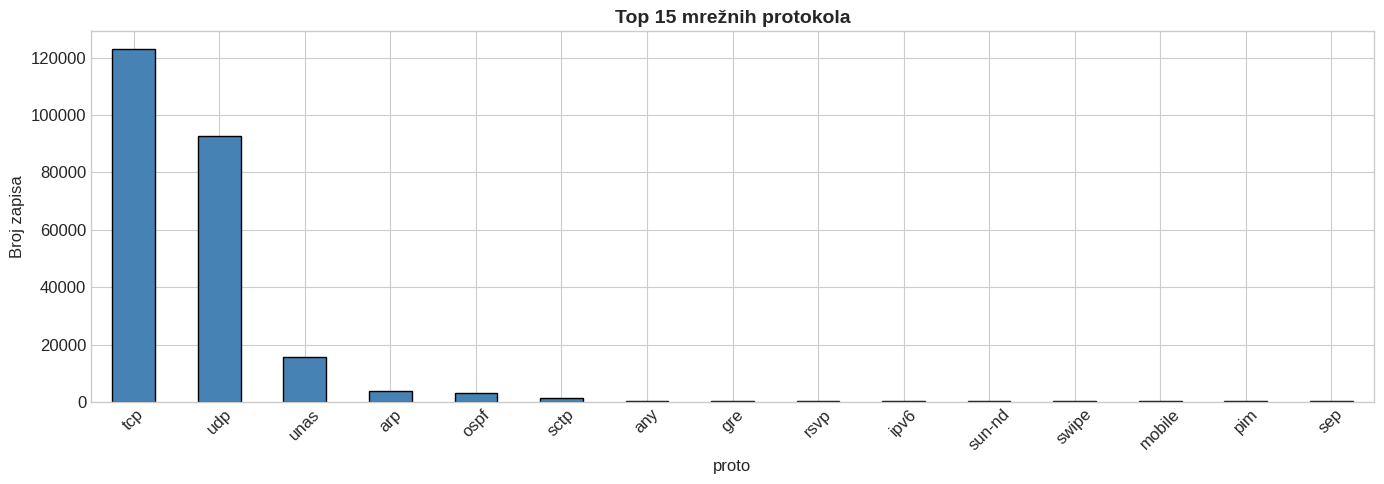

In [11]:
# Analiza 'proto' kolone (protokol)
print('=== Top 15 protokola ===')
proto_counts = df['proto'].value_counts()
display(proto_counts.head(15))

fig, ax = plt.subplots(figsize=(14, 5))
proto_counts.head(15).plot(kind='bar', ax=ax, color='steelblue', edgecolor='black')
ax.set_title('Top 15 mrežnih protokola', fontsize=14, fontweight='bold')
ax.set_ylabel('Broj zapisa')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

=== Distribucija servisa ===


,count
service,
-,141321
dns,68661
http,27011
smtp,6909
ftp-data,5391
ftp,4980
pop3,1528
ssh,1506
dhcp,120


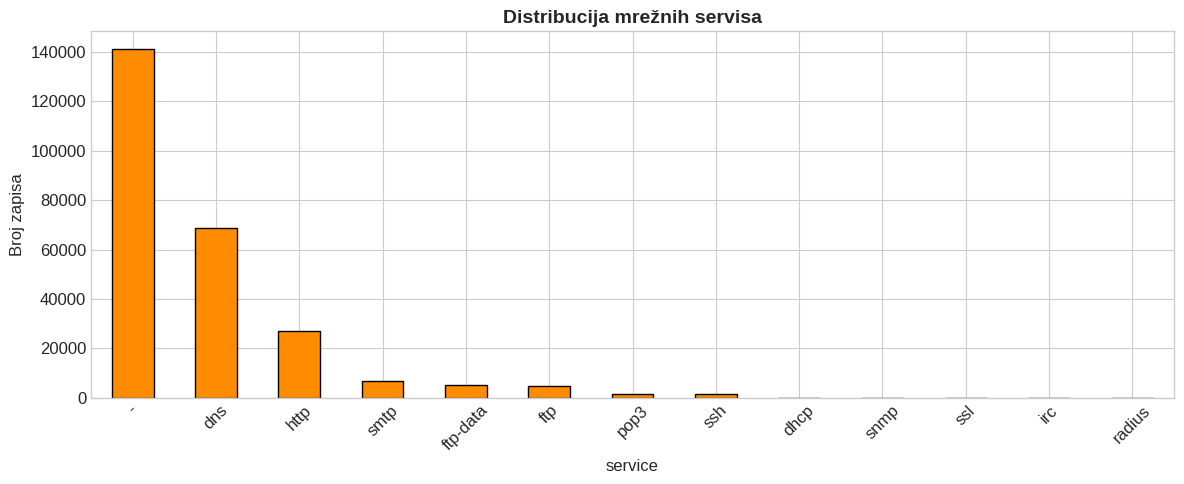

In [12]:
# Analiza 'service' kolone
print('=== Distribucija servisa ===')
service_counts = df['service'].value_counts()
display(service_counts)

fig, ax = plt.subplots(figsize=(12, 5))
service_counts.plot(kind='bar', ax=ax, color='darkorange', edgecolor='black')
ax.set_title('Distribucija mrežnih servisa', fontsize=14, fontweight='bold')
ax.set_ylabel('Broj zapisa')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

=== Distribucija stanja konekcije ===


,count
state,
FIN,117164
INT,116438
CON,20134
REQ,3833
RST,84
ECO,12
ACC,4
PAR,1
URN,1


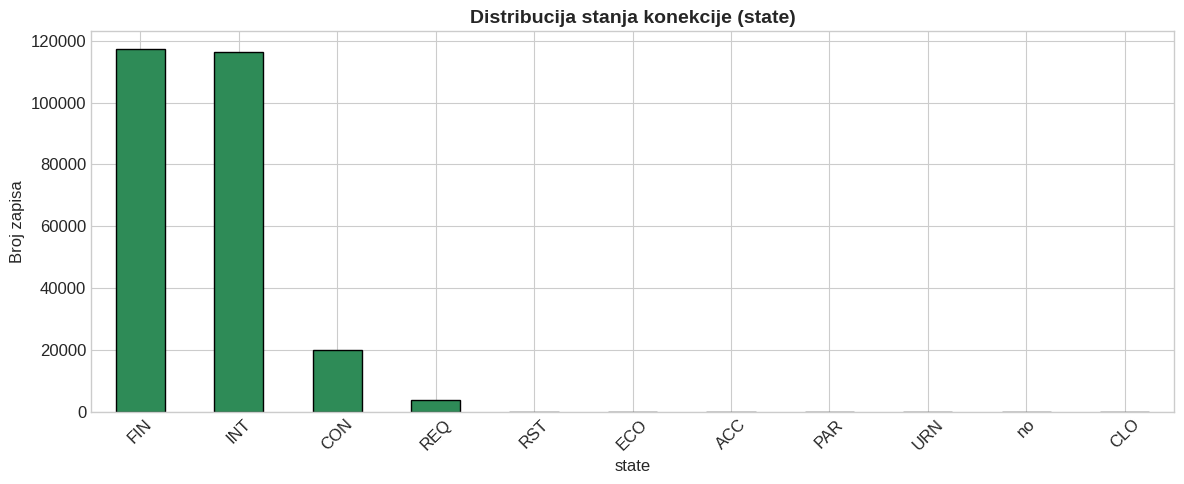

In [13]:
# Analiza 'state' kolone
print('=== Distribucija stanja konekcije ===')
state_counts = df['state'].value_counts()
display(state_counts)

fig, ax = plt.subplots(figsize=(12, 5))
state_counts.plot(kind='bar', ax=ax, color='seagreen', edgecolor='black')
ax.set_title('Distribucija stanja konekcije (state)', fontsize=14, fontweight='bold')
ax.set_ylabel('Broj zapisa')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

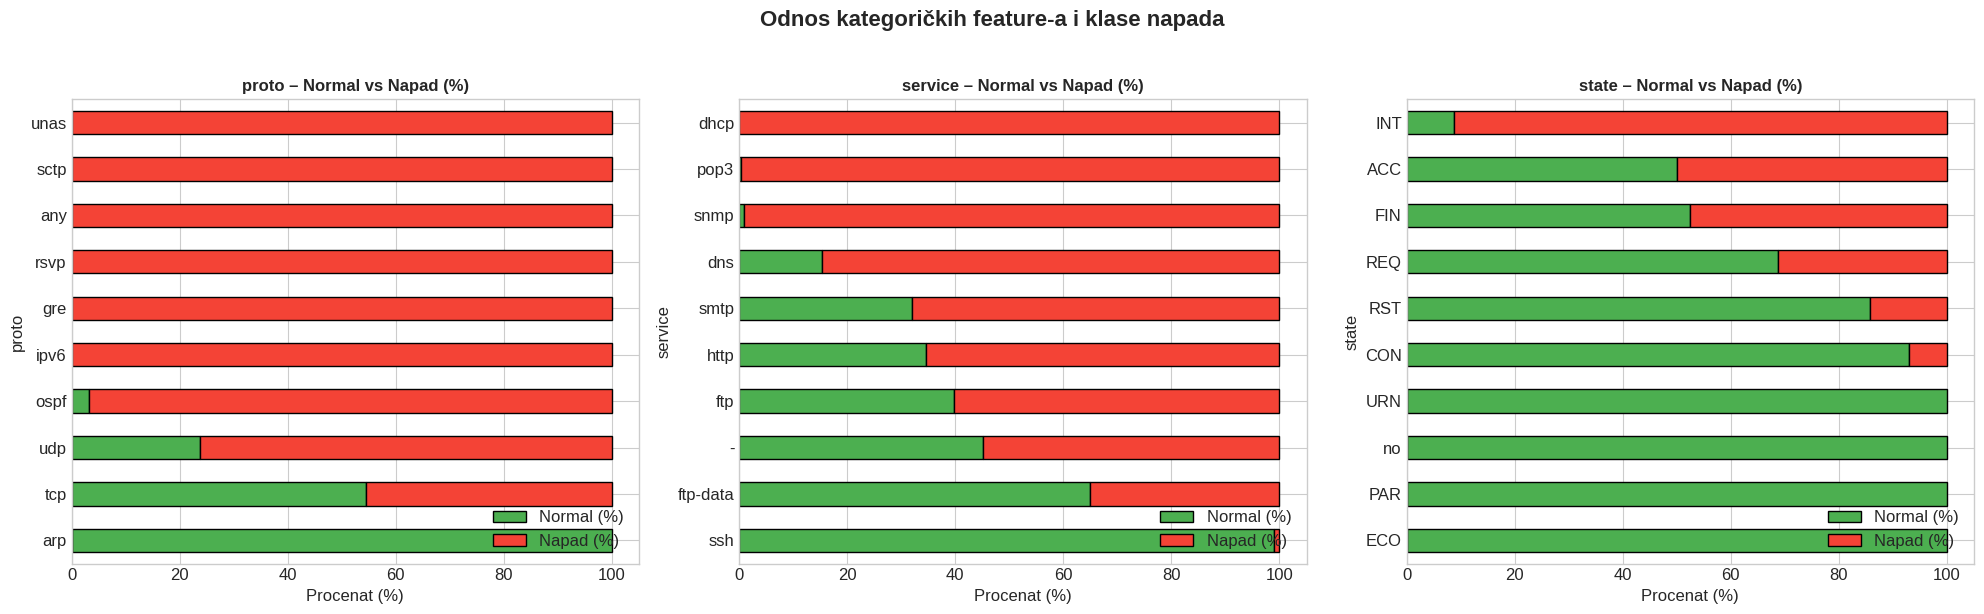

In [15]:
# Odnos kategoričkih feature-a i napada
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

colors = ['#4CAF50', '#F44336']

for idx, col in enumerate(['proto', 'service', 'state']):
    top_vals = df[col].value_counts().head(10).index
    subset = df[df[col].isin(top_vals)]
    ct = pd.crosstab(subset[col], subset['label'], normalize='index') * 100
    ct.columns = ['Normal (%)', 'Napad (%)']
    ct.sort_values('Napad (%)', ascending=True).plot(
        kind='barh', stacked=True, ax=axes[idx], color=colors, edgecolor='black'
    )
    axes[idx].set_title(f'{col} – Normal vs Napad (%)', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Procenat (%)')
    axes[idx].legend(loc='lower right')

plt.suptitle('Odnos kategoričkih feature-a i klase napada', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

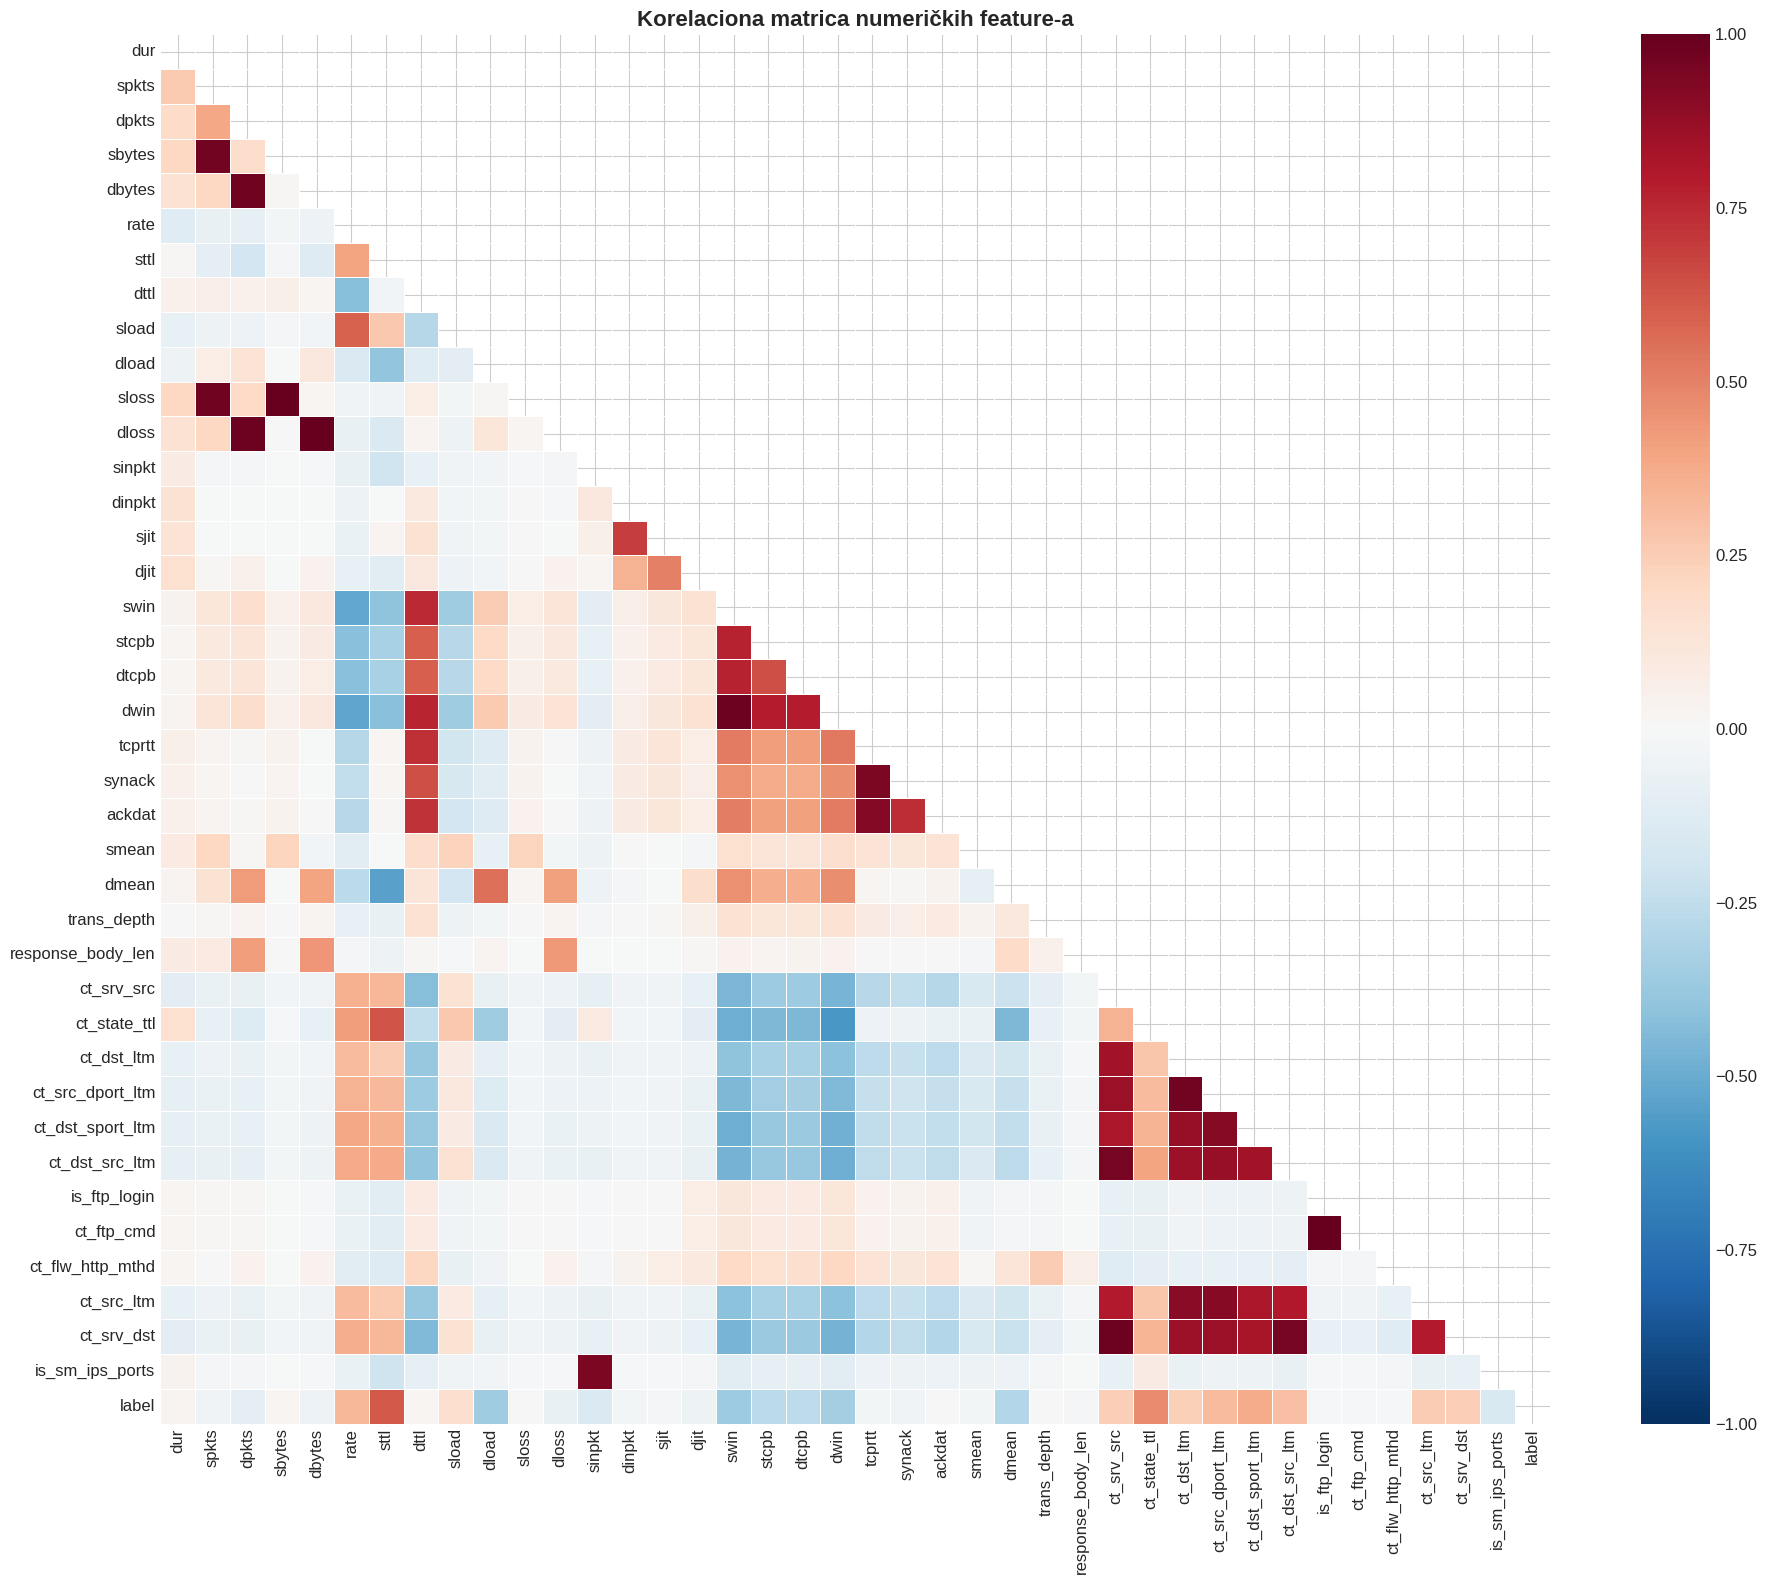

In [18]:
# Korelaciona matrica
corr_matrix = df[numeric_features + ['label']].corr()

# Heatmapa
fig, ax = plt.subplots(figsize=(20, 16))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=False, cmap='RdBu_r', center=0,
            square=True, linewidths=0.5, ax=ax, vmin=-1, vmax=1)
ax.set_title('Korelaciona matrica numeričkih feature-a', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

=== Top 20 feature-a po korelaciji sa label-om ===


,label
sttl,0.6241
ct_state_ttl,0.4766
ct_dst_sport_ltm,0.3717
swin,-0.3649
dload,-0.3522
dwin,-0.3392
rate,0.3359
ct_src_dport_ltm,0.3185
ct_dst_src_ltm,0.2996
dmean,-0.2952


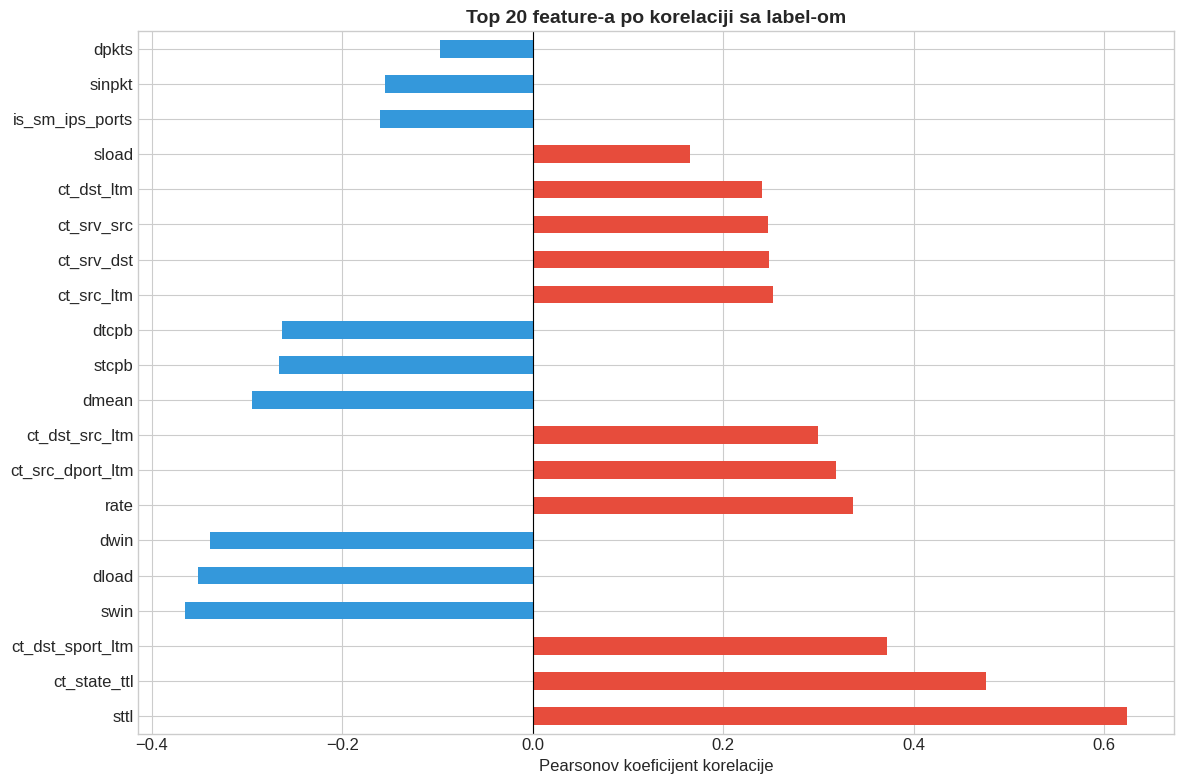

In [19]:
# Korelacija sa ciljnom varijablom (label)
label_corr = corr_matrix['label'].drop('label').sort_values(key=abs, ascending=False)

print('=== Top 20 feature-a po korelaciji sa label-om ===')
display(label_corr.head(20))

fig, ax = plt.subplots(figsize=(12, 8))
label_corr.head(20).plot(kind='barh', ax=ax, color=label_corr.head(20).apply(
    lambda x: '#e74c3c' if x > 0 else '#3498db'
))
ax.set_title('Top 20 feature-a po korelaciji sa label-om', fontsize=14, fontweight='bold')
ax.set_xlabel('Pearsonov koeficijent korelacije')
ax.axvline(x=0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

In [20]:
# Visoko korelisani parovi feature-a (potencijalni kandidati za uklanjanje)
print('=== Visoko korelisani parovi feature-a (|r| > 0.85) ===')
high_corr_pairs = []

for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) > 0.85:
            high_corr_pairs.append({
                'Feature 1': corr_matrix.columns[i],
                'Feature 2': corr_matrix.columns[j],
                'Korelacija': round(corr_matrix.iloc[i, j], 4)
            })

high_corr_df = pd.DataFrame(high_corr_pairs).sort_values('Korelacija', key=abs, ascending=False)
display(high_corr_df)
print(f'\nUkupno visoko korelisanih parova: {len(high_corr_df)}')

=== Visoko korelisani parovi feature-a (|r| > 0.85) ===


,Feature 1,Feature 2,Korelacija
23,is_ftp_login,ct_ftp_cmd,0.9989
5,dbytes,dloss,0.9967
4,sbytes,sloss,0.9958
7,swin,dwin,0.9805
3,dpkts,dloss,0.9796
12,ct_srv_src,ct_srv_dst,0.9795
2,dpkts,dbytes,0.9734
1,spkts,sloss,0.9719
0,spkts,sbytes,0.9644
13,ct_dst_ltm,ct_src_dport_ltm,0.9615



Ukupno visoko korelisanih parova: 24
